<a href="https://colab.research.google.com/github/sundrasubramaniyanr-sudo/News-Classification-ML/blob/main/News_Classification_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/sundrasubramaniyanr-sudo/News-Classification-ML.git

Cloning into 'News-Classification-ML'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 21 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (21/21), 2.65 MiB | 26.89 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [2]:
!ls -R News-Classification-ML

News-Classification-ML:
DATASET.rar  MAIN.py  README.md  REQUIRMENTS.txt  results

News-Classification-ML/results:
comparison.csv		performance_comparison.png  what_if_experiment.png
confusion_matrices.png	what_if_experiment.csv


In [3]:
!sudo apt-get install unrar -y
!unrar x News-Classification-ML/DATASET.rar News-Classification-ML/dataset/

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from News-Classification-ML/DATASET.rar

Creating    News-Classification-ML/dataset                            OK
Creating    News-Classification-ML/dataset/DATASET                    OK
Creating    News-Classification-ML/dataset/DATASET/business           OK
Extracting  News-Classification-ML/dataset/DATASET/business/001.txt        0%  OK 
Extracting  News-Classification-ML/dataset/DATASET/business/002.txt        0%  OK 
Extracting  News-Classification-ML/dataset/DATASET/business/003.txt        0%  OK 
Extracting  News-Classification-ML/dataset/DATASET/business/004.txt        0%  OK 
Extracting  News-Classification-ML/dataset/DATASET/business/005.txt      

In [4]:
import os

dataset_path = "News-Classification-ML/dataset"

for folder in sorted(os.listdir(dataset_path)):
    path = os.path.join(dataset_path, folder)
    if os.path.isdir(path):
        print(folder, ":", len(os.listdir(path)), "files")

DATASET : 6 files


In [5]:
!find News-Classification-ML/dataset -maxdepth 3 -type d

News-Classification-ML/dataset
News-Classification-ML/dataset/DATASET
News-Classification-ML/dataset/DATASET/sport
News-Classification-ML/dataset/DATASET/business
News-Classification-ML/dataset/DATASET/entertainment
News-Classification-ML/dataset/DATASET/politics
News-Classification-ML/dataset/DATASET/tech


In [6]:
import os

dataset_path = "News-Classification-ML/dataset/DATASET"

total = 0

for category in sorted(os.listdir(dataset_path)):
    folder = os.path.join(dataset_path, category)

    if os.path.isdir(folder):
        count = len([
            f for f in os.listdir(folder)
            if f.endswith(".txt")
        ])
        print(category, ":", count)
        total += count

print("\nTOTAL ARTICLES:", total)

business : 510
entertainment : 386
politics : 417
sport : 511
tech : 401

TOTAL ARTICLES: 2225


In [7]:
!pip install pandas scikit-learn matplotlib seaborn


In [8]:
!ls News-Classification-ML/


dataset  DATASET.rar  MAIN.py  README.md  REQUIRMENTS.txt  results


In [9]:
!grep -n "dataset" News-Classification-ML/MAIN.py

29:DATASET_PATH = Path("dataset")


In [10]:
!sed -i 's|DATASET_PATH = Path("dataset")|DATASET_PATH = Path("dataset/DATASET")|' News-Classification-ML/MAIN.py

In [11]:
!grep -n "DATASET_PATH" News-Classification-ML/MAIN.py

29:DATASET_PATH = Path("dataset/DATASET")
42:    folder = DATASET_PATH / category


In [12]:
%cd /content/News-Classification-ML
!python MAIN.py

/content/News-Classification-ML
Total documents: 2225
Categories: ['business', 'entertainment', 'politics', 'sport', 'tech']

Training documents: 1780
Testing documents: 445

TF-IDF feature extraction completed!
Number of features: 5000

Training: Decision Tree

Classification Report:
               precision    recall  f1-score   support

     business       0.79      0.83      0.81       102
entertainment       0.84      0.79      0.81        77
     politics       0.84      0.87      0.85        84
        sport       0.88      0.87      0.88       102
         tech       0.84      0.81      0.83        80

     accuracy                           0.84       445
    macro avg       0.84      0.84      0.84       445
 weighted avg       0.84      0.84      0.84       445


Training: KNN

Classification Report:
               precision    recall  f1-score   support

     business       0.98      0.94      0.96       102
entertainment       0.97      0.99      0.98        77
     politi

In [13]:
!ls -lh results/


total 152K
-rw-r--r-- 1 root root 383 Oct 31 22:04 comparison.csv
-rw-r--r-- 1 root root 88K Oct 31 22:04 confusion_matrices.png
-rw-r--r-- 1 root root 34K Oct 31 22:04 performance_comparison.png
-rw-r--r-- 1 root root  91 Oct 31 22:04 what_if_experiment.csv
-rw-r--r-- 1 root root 18K Oct 31 22:04 what_if_experiment.png


performance_comparison.png


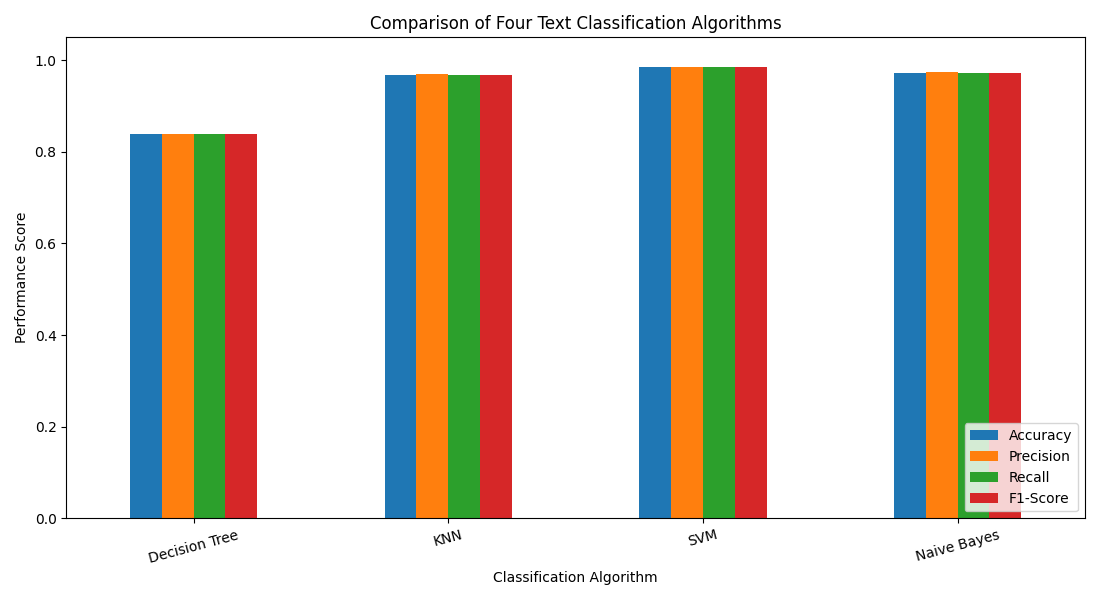

confusion_matrices.png


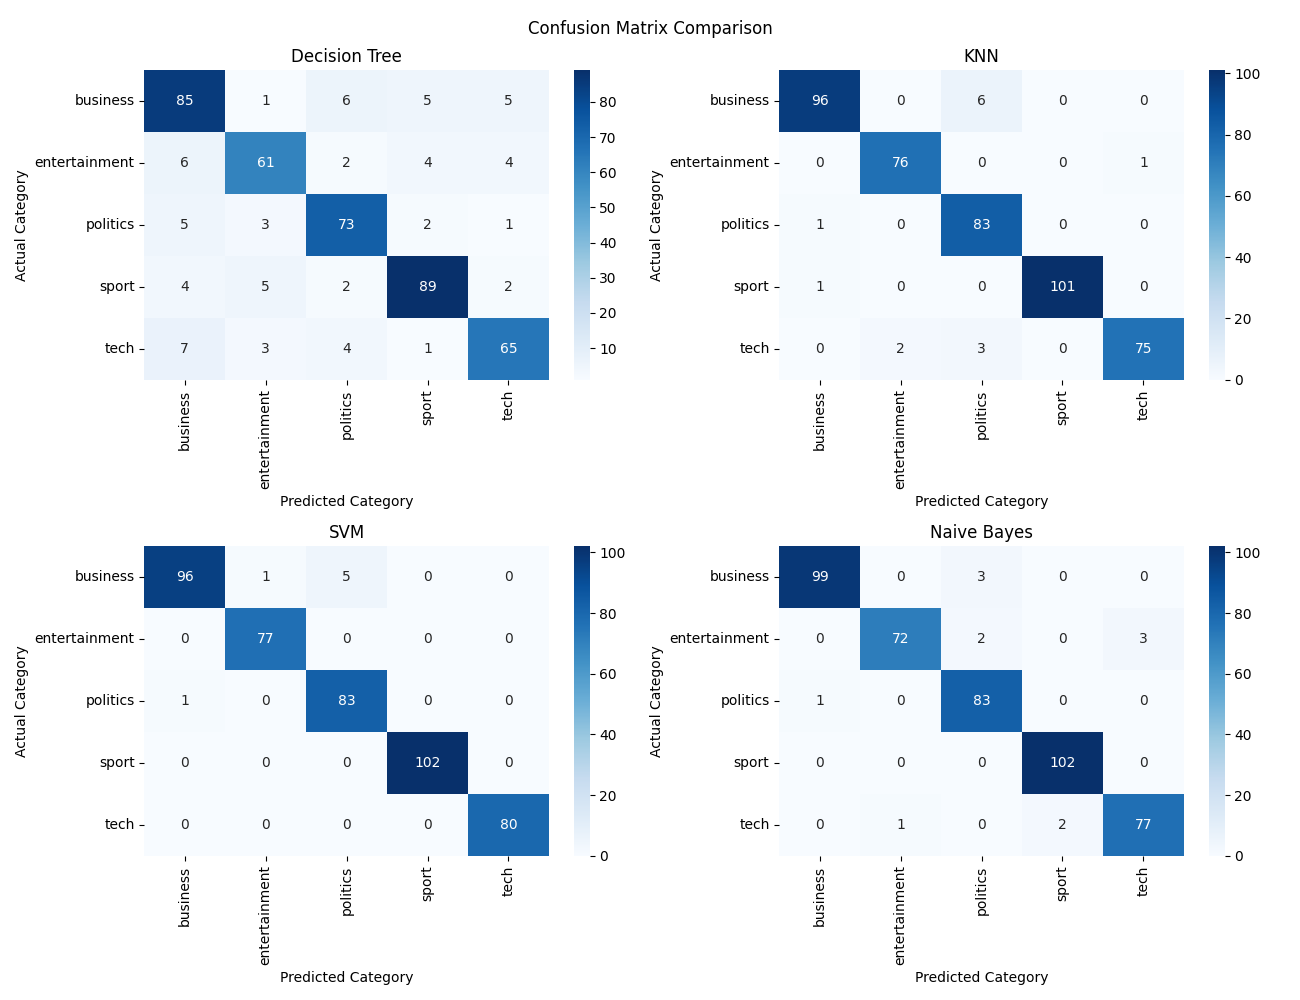

what_if_experiment.png


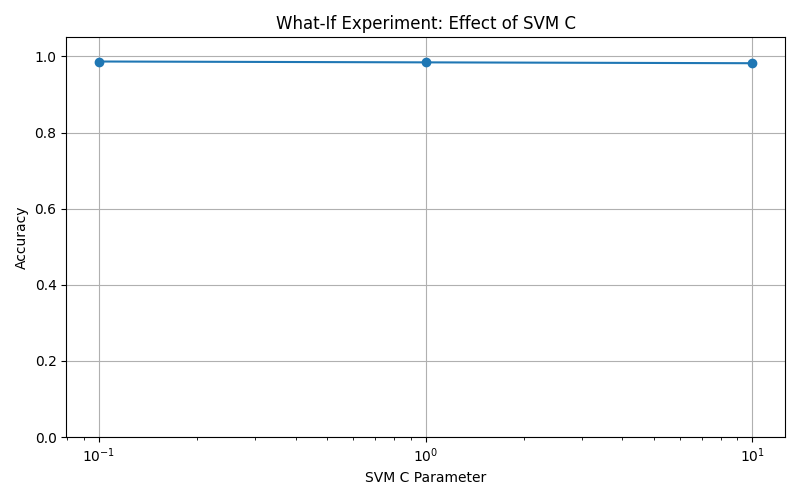

In [14]:
from IPython.display import display, Image
import os

for filename in [
    "performance_comparison.png",
    "confusion_matrices.png",
    "what_if_experiment.png"
]:
    path = f"results/{filename}"
    if os.path.exists(path):
        print(filename)
        display(Image(filename=path))